# Exercise 2: Image Blending using OpenCV
**Objective:** load two images, resize to match, blend with `cv2.addWeighted`, display and save.

Place your own two images next to this notebook as `image1.jpg` and `image2.jpg`. If they are missing, the notebook generates two sample images so it still runs.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load images (fallback to generated samples if files are absent)
img1 = cv2.imread('image1.jpg')
img2 = cv2.imread('image2.jpg')
if img1 is None or img2 is None:
    print('image1.jpg / image2.jpg not found - generating sample images')
    img1 = np.zeros((400,600,3), np.uint8)
    for x in range(600): img1[:,x] = (int(255*x/600), 80, 255-int(255*x/600))
    cv2.circle(img1,(300,200),100,(255,255,255),-1)
    img2 = np.zeros((400,600,3), np.uint8)
    for y in range(400): img2[y,:] = (50, int(255*y/400), 200)
    cv2.rectangle(img2,(150,100),(450,300),(255,255,0),-1)
    cv2.imwrite('image1.jpg', img1); cv2.imwrite('image2.jpg', img2)

# Resize image2 to match image1 dimensions
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))
print('Image shapes:', img1.shape, img2.shape)

Image shapes: (800, 1200, 3) (800, 1200, 3)


In [2]:
# Step 2: Weighted blending: result = 0.6*img1 + 0.4*img2 + 0
alpha, beta = 0.6, 0.4
blended = cv2.addWeighted(img1, alpha, img2, beta, 0)

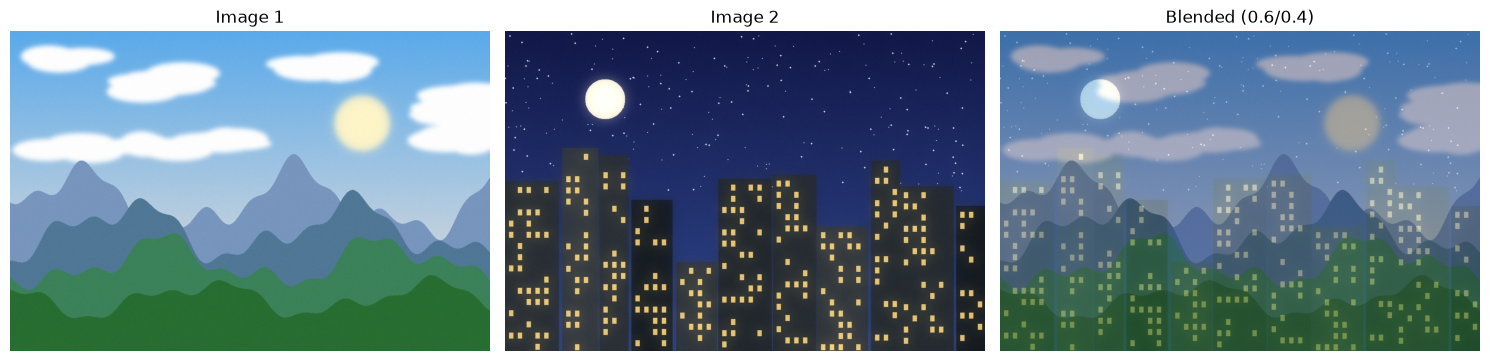

In [3]:
# Step 3: Display and save
cv2.imwrite('blended.jpg', blended)
fig, ax = plt.subplots(1, 3, figsize=(15,5))
for a, im, t in zip(ax, [img1, img2, blended], ['Image 1', 'Image 2', 'Blended (0.6/0.4)']):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))  # OpenCV is BGR, matplotlib is RGB
    a.set_title(t); a.axis('off')
plt.tight_layout()
plt.savefig('comparison.png', dpi=150)
plt.show()